# Experiment 2 — fresh run with every epoch visible
## tl;dr
This notebook actually retrains the Arsenal-only baseline, independently initialized league challenger, and optional Arsenal fine-tuning (enabled). Every epoch is printed during execution and exported to CSV and text. The results below are computed by this execution.

**Reproducibility rerun after test inspection.** Identical data, settings and per-fit seed resets can reproduce identical results. This is not independent confirmatory evidence. The earlier run and experiment 1 remain archived.

**Observed:** 221 completed epochs and 3,684 optimizer updates. Every validation/test probability exactly matches experiment 1. Arsenal test log loss: baseline 0.959723, league 0.899941, fine-tuned 0.900410. Complete per-epoch tables and checkpoint ancestry follow.

## Context & Methods
Experiment 1 ran league → Arsenal → fine-tuning. Experiment 2 establishes the Arsenal baseline first, then initializes the league challenger independently from seed 42; it never initializes the challenger from the Arsenal checkpoint. Optional fine-tuning starts only from the best league checkpoint, keeps its scaler, resets AdamW, and trains on Arsenal training rows. We enable that predefined stage here; disable `FINE_TUNE` to omit it.

The training loop is reviewed and instrumented in `experiments/epoch_training.py`, preserving experiment 1 update and stopping rules. Epoch logging consumes no random numbers. Cross-entropy; AdamW lr=1e-4, weight decay=0.01; batch 256; architecture 39→32→16→3, ReLU/dropout 0.1; maximum 100 epochs per fit; patience 20, min_delta=1e-4. Each fit resets seed 42. Checkpoints minimize the same Arsenal validation loss; fine-tuning allows epoch zero. Logistic and prior controls stay unchanged. Candidate selection includes all controls and uses validation only.

### Key Assumptions
Frozen data and 39-feature allowlist are unchanged. Train: 2000/01–2021/22; validation: 2022/23–2023/24; test: 2024/25–2025/26. Preprocessing fits on each model's training population. League-wide includes Arsenal training fixtures, as before; independent means independent model initialization, not disjoint data. The same 74 Arsenal validation and 75 test fixtures are used. Test scores never choose checkpoints, stage inclusion, or candidates. No new untouched holdout is claimed.

Run from a checkout with `python -m pip install -r requirements.txt` (CPU torch 2.5.1+cpu is compatible). Execute all cells to create a new timestamped run. Experiment 1 artifacts are read only. Source: [protocol](../EXPERIMENT_PROTOCOL.md) and `results/run_20261024T140407` at commit `a31974478432a717fb2986887e81f8739990ea17`.

In [1]:
from pathlib import Path
import sys, json
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/experiment_2.py').exists())
sys.path.insert(0, str(PROJECT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from experiments import experiment_2 as experiment
from experiments import train
FINE_TUNE = True
REFERENCE = PROJECT/'results/run_20261024T140407'
plt.rcParams.update({'figure.figsize': (10, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

## Data
### Verify frozen inputs before fitting
Fail if any input, split, feature order, or configuration differs from experiment 1. No downloads or data rebuilding occur.

In [2]:
reference_manifest = json.loads((REFERENCE/'run_manifest.json').read_text())
assert experiment.CONFIG == reference_manifest['config']
assert train.digest(PROJECT/'experiments/train.py') == reference_manifest['code_sha256']
for name, expected in reference_manifest['input_sha256'].items():
    assert train.digest(experiment.DATA/'data'/name) == expected, name
schema, splits = experiment.load()
assert schema['features'] == reference_manifest['features']
display(pd.DataFrame([{'split': s, 'league_rows': len(y), 'Arsenal_rows': int(experiment.arsenal(m).sum())} for s, (x, y, m) in splits.items()]))

,split,league_rows,Arsenal_rows
0,train,7977,815
1,validation,730,74
2,test,732,75


### Execute the reordered workflow
No experiment 1 checkpoint is reused for training. The independent Arsenal and league fits each start fresh; only the optional fine-tuning stage receives an initial checkpoint. New checkpoints, histories, probabilities, metrics and provenance are saved below.

In [3]:
RUN = experiment.run(fine_tune=FINE_TUNE)
print('New run:', RUN.relative_to(PROJECT))
training = pd.read_csv(RUN/'training_summary.csv')
expected_order = ['arsenal_mlp', 'league_mlp'] + (['league_to_arsenal_mlp'] if FINE_TUNE else [])
assert training.model.tolist() == expected_order
assert training.epochs_run.le(100).all()
manifest = json.loads((RUN/'run_manifest.json').read_text())
assert manifest['input_sha256'] == reference_manifest['input_sha256']
assert manifest['config'] == reference_manifest['config']
for row in training.itertuples():
    checkpoint = torch.load(RUN/f'{row.model}_best.pt', map_location='cpu', weights_only=False)
    if row.model in ['arsenal_mlp', 'league_mlp']:
        assert checkpoint['initial_checkpoint'] is None
    else:
        assert Path(checkpoint['initial_checkpoint']) == RUN/'league_mlp_best.pt'
        league_checkpoint = torch.load(RUN/'league_mlp_best.pt', map_location='cpu', weights_only=False)
        assert checkpoint['scaler_mean'] == league_checkpoint['scaler_mean']
        assert checkpoint['scaler_scale'] == league_checkpoint['scaler_scale']
display(training.drop(columns='checkpoint_sha256'))


START arsenal_mlp: seed=42, initial=None, rows=815


arsenal_mlp epoch=001 train_loss=1.089137971 val_loss=1.081805110 val_acc=0.486486 best_epoch=001 saved=True patience=0/20 steps=4


arsenal_mlp epoch=002 train_loss=1.086166256 val_loss=1.079540133 val_acc=0.513514 best_epoch=002 saved=True patience=0/20 steps=8


arsenal_mlp epoch=003 train_loss=1.084127313 val_loss=1.077311635 val_acc=0.527027 best_epoch=003 saved=True patience=0/20 steps=12


arsenal_mlp epoch=004 train_loss=1.082825731 val_loss=1.075055599 val_acc=0.527027 best_epoch=004 saved=True patience=0/20 steps=16


arsenal_mlp epoch=005 train_loss=1.080569366 val_loss=1.072783828 val_acc=0.540541 best_epoch=005 saved=True patience=0/20 steps=20


... (220 outputs left out)

league_to_arsenal_mlp epoch=021 train_loss=0.903576806 val_loss=0.799120426 val_acc=0.702703 best_epoch=001 saved=False patience=20/20 steps=84


END league_to_arsenal_mlp: best_epoch=1, epochs=21, stop=patience


New run: results/experiment_2/run_20261026T002228


,model,best_epoch,epochs_run,validation_arsenal_log_loss,training_rows
0,arsenal_mlp,100,100,0.864435,815
1,league_mlp,98,100,0.796609,7977
2,league_to_arsenal_mlp,1,21,0.796373,815


### Every epoch and execution evidence
Training loss is the online minibatch average with dropout active; validation loss and accuracy use evaluation mode. Patience uses the original min_delta rule. No per-epoch test evaluation occurs. Full tables follow without row truncation. Epoch zero for fine-tuning appears in the training output; it is the inherited league checkpoint, before any fine-tuning update.

In [4]:
from IPython.display import Markdown
execution = {name: json.loads((RUN/f'{name}_execution.json').read_text()) for name in expected_order}
assert execution['arsenal_mlp']['initial_checkpoint'] is None
assert execution['league_mlp']['initial_checkpoint'] is None
assert execution['arsenal_mlp']['initial_weights_sha256'] == execution['league_mlp']['initial_weights_sha256']
if FINE_TUNE:
    assert execution['league_to_arsenal_mlp']['initial_weights_sha256'] == execution['league_mlp']['best_weights_sha256']
    assert execution['league_to_arsenal_mlp']['initial_checkpoint_sha256'] == train.digest(RUN/'league_mlp_best.pt')
all_epochs = []
for name in expected_order:
    h = pd.read_csv(RUN/f'{name}_history.csv')
    assert h.epoch.tolist() == list(range(1,len(h)+1))
    steps_per_epoch = int(np.ceil(execution[name]['training_rows']/experiment.CONFIG['batch_size']))
    assert h.optimizer_steps.tolist() == [steps_per_epoch*i for i in h.epoch]
    assert execution[name]['optimizer_steps'] == int(h.optimizer_steps.iloc[-1])
    display(Markdown('**'+name+' — every epoch**'))
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(h.round(9))
    all_epochs.append(h.assign(model=name))
pd.concat(all_epochs, ignore_index=True).to_csv(RUN/'all_epochs.csv',index=False)
display(pd.DataFrame(execution).T)


**arsenal_mlp — every epoch**

,epoch,training_log_loss,validation_arsenal_log_loss,validation_arsenal_accuracy,best_validation_loss,best_epoch_so_far,checkpoint_saved,patience_used,optimizer_steps,epoch_seconds
0,1,1.089138,1.081805,0.486486,1.081805,1,True,0,4,0.014626
1,2,1.086166,1.079540,0.513514,1.079540,2,True,0,8,0.003807
2,3,1.084127,1.077312,0.527027,1.077312,3,True,0,12,0.003565
3,4,1.082826,1.075056,0.527027,1.075056,4,True,0,16,0.004815
4,5,1.080569,1.072784,0.540541,1.072784,5,True,0,20,0.003438
5,6,1.079655,1.070475,0.540541,1.070475,6,True,0,24,0.003240
6,7,1.076868,1.068149,0.540541,1.068149,7,True,0,28,0.003527
7,8,1.074225,1.065802,0.540541,1.065802,8,True,0,32,0.003336
8,9,1.072349,1.063411,0.540541,1.063411,9,True,0,36,0.003439
9,10,1.073181,1.060987,0.554054,1.060987,10,True,0,40,0.003301


**league_mlp — every epoch**

,epoch,training_log_loss,validation_arsenal_log_loss,validation_arsenal_accuracy,best_validation_loss,best_epoch_so_far,checkpoint_saved,patience_used,optimizer_steps,epoch_seconds
0,1,1.087098,1.068020,0.540541,1.068020,1,True,0,32,0.022781
1,2,1.076027,1.047609,0.594595,1.047609,2,True,0,64,0.020156
2,3,1.064099,1.023565,0.608108,1.023565,3,True,0,96,0.019347
3,4,1.051737,0.998163,0.648649,0.998163,4,True,0,128,0.022029
4,5,1.040045,0.972663,0.662162,0.972663,5,True,0,160,0.020792
5,6,1.028717,0.949228,0.675676,0.949228,6,True,0,192,0.023071
6,7,1.019569,0.928597,0.675676,0.928597,7,True,0,224,0.019506
7,8,1.011865,0.911380,0.675676,0.911380,8,True,0,256,0.019944
8,9,1.006175,0.897544,0.675676,0.897544,9,True,0,288,0.021080
9,10,1.003229,0.886274,0.675676,0.886274,10,True,0,320,0.024522


**league_to_arsenal_mlp — every epoch**

,epoch,training_log_loss,validation_arsenal_log_loss,validation_arsenal_accuracy,best_validation_loss,best_epoch_so_far,checkpoint_saved,patience_used,optimizer_steps,epoch_seconds
0,1,0.906066,0.796373,0.689189,0.796373,1,True,0,4,0.168362
1,2,0.901878,0.796407,0.689189,0.796373,1,False,1,8,0.003491
2,3,0.909410,0.796657,0.689189,0.796373,1,False,2,12,0.002617
3,4,0.904080,0.796975,0.689189,0.796373,1,False,3,16,0.003196
4,5,0.907378,0.797208,0.689189,0.796373,1,False,4,20,0.002408
5,6,0.905636,0.797432,0.689189,0.796373,1,False,5,24,0.002388
6,7,0.904114,0.797634,0.689189,0.796373,1,False,6,28,0.002611
7,8,0.901585,0.797771,0.689189,0.796373,1,False,7,32,0.002579
8,9,0.896478,0.797894,0.689189,0.796373,1,False,8,36,0.002933
9,10,0.902493,0.798029,0.689189,0.796373,1,False,9,40,0.002573


,model,started_utc,initial_checkpoint,initial_weights_sha256,initial_checkpoint_sha256,training_rows,validation_rows,optimizer_steps,finished_utc,elapsed_seconds,best_weights_sha256,best_epoch,epochs_run,stop_reason
arsenal_mlp,arsenal_mlp,2026-10-26T00:22:28.116806+00:00,None,a82b44ca3abc7438de0fbd0854c518ff90448624564e79...,None,815,74,400,2026-10-26T00:22:29.311930+00:00,1.208678,09e8eea1851b750f2da9bb1b27f73c1100002ebc1f3ab8...,100,100,maximum epochs
league_mlp,league_mlp,2026-10-26T00:22:29.319139+00:00,None,a82b44ca3abc7438de0fbd0854c518ff90448624564e79...,None,7977,74,3200,2026-10-26T00:22:31.623025+00:00,2.309313,6491ec3acec3c202f9476ed554dad683191400613eb8a9...,98,100,maximum epochs
league_to_arsenal_mlp,league_to_arsenal_mlp,2026-10-26T00:22:31.626593+00:00,/workspace/Premier-League-Research/results/exp...,6491ec3acec3c202f9476ed554dad683191400613eb8a9...,0416130b3fd2eab7db5f86512162569e862c82f5014f61...,815,74,84,2026-10-26T00:22:31.881974+00:00,0.257653,1ef8bbf329a100e20134b3d4f3bc6d3148faab625b3bdc...,1,21,patience


## Results
### Training curves and saved checkpoints
Best epochs are selected using Arsenal validation only. Reaching the cap means the search budget was exhausted, not that a global optimum was found.

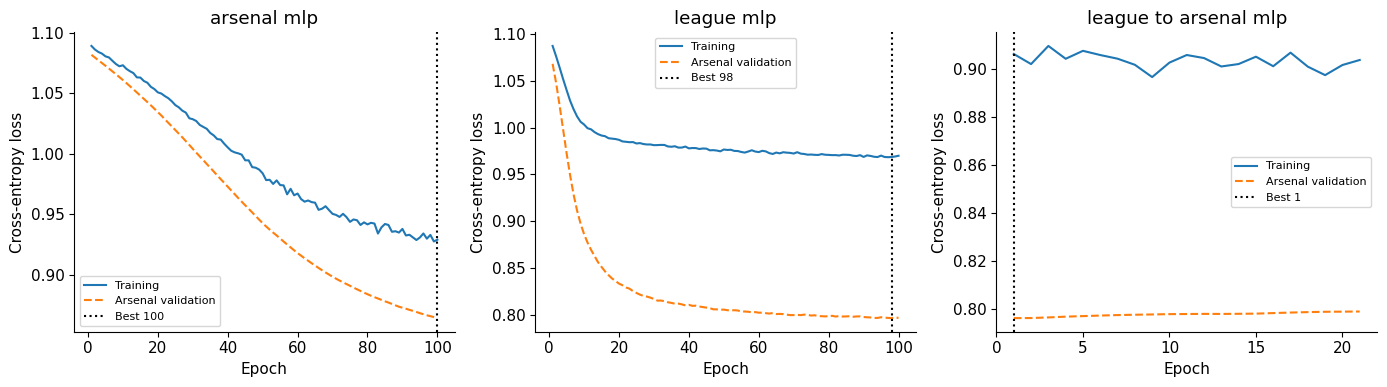

In [5]:
fig, axes = plt.subplots(1, len(training), figsize=(14,4), squeeze=False)
for ax, row in zip(axes[0], training.itertuples()):
    history = pd.read_csv(RUN/f'{row.model}_history.csv')
    ax.plot(history.epoch, history.training_log_loss, label='Training')
    ax.plot(history.epoch, history.validation_arsenal_log_loss, '--', label='Arsenal validation')
    ax.axvline(row.best_epoch, color='black', linestyle=':', label=f'Best {row.best_epoch}')
    ax.set(title=row.model.replace('_',' '), xlabel='Epoch', ylabel='Cross-entropy loss')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN/'learning_curves.png', dpi=140)
plt.show()

### Compare all metrics with experiment 1
The paired table reports the same model, split and population. Deltas are experiment 2 minus experiment 1. Exact prediction comparisons establish whether execution order changes the fitted models.

In [6]:
metrics = pd.read_csv(RUN/'metrics.csv')
reference_metrics = pd.read_csv(REFERENCE/'metrics.csv')
comparison = metrics.merge(reference_metrics, on=['model','split','population'], suffixes=('_exp2','_exp1'), validate='one_to_one')
for metric in ['log_loss','brier_multiclass','accuracy']:
    comparison[metric+'_delta'] = comparison[metric+'_exp2'] - comparison[metric+'_exp1']
assert comparison.n_exp2.eq(comparison.n_exp1).all()
comparison.to_csv(RUN/'experiment_1_comparison.csv', index=False)
arsenal_test = comparison.query("split == 'test' and population == 'Arsenal'")
display(arsenal_test[['model','log_loss_exp1','log_loss_exp2','log_loss_delta','brier_multiclass_exp2','accuracy_exp2','n_exp2']].round(6))
checks = []
for model in metrics.model.unique():
    for split in ['validation','test']:
        old = pd.read_csv(REFERENCE/f'{model}_{split}_predictions.csv')
        new = pd.read_csv(RUN/f'{model}_{split}_predictions.csv')
        pd.testing.assert_frame_equal(old.drop(columns=['p_A','p_D','p_H']), new.drop(columns=['p_A','p_D','p_H']))
        difference = float(np.abs(old[['p_A','p_D','p_H']].to_numpy()-new[['p_A','p_D','p_H']].to_numpy()).max())
        checks.append({'model':model,'split':split,'max_probability_difference':difference})
    if model in expected_order:
        restored = train.predict_checkpoint(RUN/f'{model}_best.pt', pd.read_csv(experiment.DATA/'data/test/X.csv'))
        saved = pd.read_csv(RUN/f'{model}_test_predictions.csv')
        np.testing.assert_allclose(restored, saved[['p_A','p_D','p_H']], rtol=1e-5, atol=1e-7)
checks = pd.DataFrame(checks)
checks.to_csv(RUN/'prediction_reproducibility.csv', index=False)
display(checks)
selection = json.loads((RUN/'selected_model.json').read_text())
assert selection['selected_model'] == min(selection['validation_scores'], key=selection['validation_scores'].get)
print('Validation-selected candidate:', selection['selected_model'])

,model,log_loss_exp1,log_loss_exp2,log_loss_delta,brier_multiclass_exp2,accuracy_exp2,n_exp2
18,arsenal_mlp,0.959723,0.959723,0.0,0.569044,0.600000,75
21,league_mlp,0.899941,0.899941,0.0,0.529087,0.613333,75
24,league_to_arsenal_mlp,0.900410,0.900410,0.0,0.529357,0.613333,75
27,league_logistic,0.908957,0.908957,0.0,0.532644,0.613333,75
30,arsenal_logistic,0.909300,0.909300,0.0,0.534445,0.640000,75
33,league_prior,1.094381,1.094381,0.0,0.664183,0.400000,75


,model,split,max_probability_difference
0,arsenal_mlp,validation,0.0
1,arsenal_mlp,test,0.0
2,league_mlp,validation,0.0
3,league_mlp,test,0.0
4,league_to_arsenal_mlp,validation,0.0
5,league_to_arsenal_mlp,test,0.0
6,league_logistic,validation,0.0
7,league_logistic,test,0.0
8,arsenal_logistic,validation,0.0
9,arsenal_logistic,test,0.0


Validation-selected candidate: league_logistic


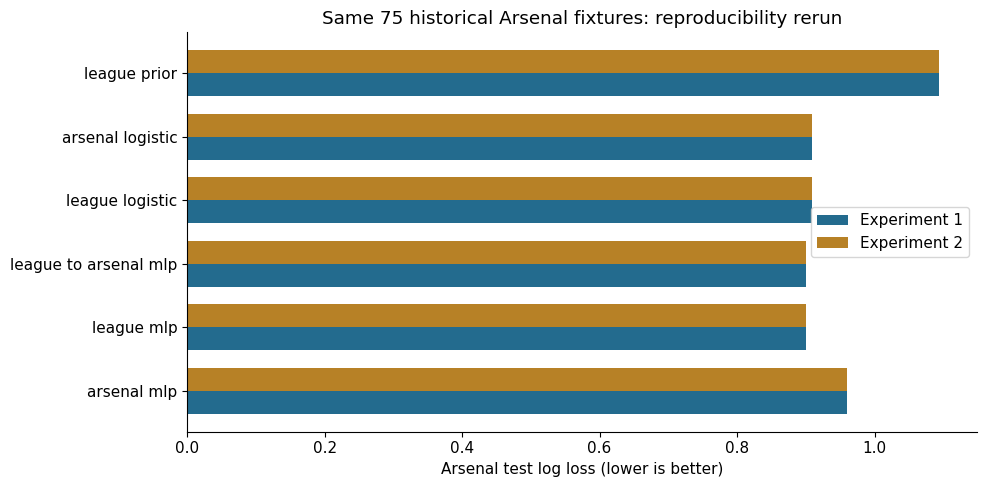

comparison                                      league_mlp minus arsenal_mlp Arsenal test log ...
difference                                                                              -0.059782
month_block_bootstrap_95_percentile_interval         [-0.10078658796846866, -0.01619370488915595]
resamples                                                                                    1000
blocks                                                                                         20
caveat                                          Single training seed; short historical test; i...
dtype: object

,model,log_loss,brier_multiclass,accuracy,n
19,arsenal_mlp,1.03934,0.62535,0.50533,657
22,league_mlp,1.03237,0.62114,0.47793,657
25,league_to_arsenal_mlp,1.03251,0.62122,0.47793,657
28,league_logistic,1.02897,0.61917,0.49163,657
31,arsenal_logistic,1.10148,0.65736,0.47793,657
34,league_prior,1.08160,0.65564,0.41857,657


In [7]:
fig, ax = plt.subplots(figsize=(10,5))
positions = np.arange(len(arsenal_test))
ax.barh(positions-.18, arsenal_test.log_loss_exp1, height=.36, label='Experiment 1', color='#236B8E')
ax.barh(positions+.18, arsenal_test.log_loss_exp2, height=.36, label='Experiment 2', color='#B78126')
ax.set_yticks(positions, arsenal_test.model.str.replace('_',' '))
ax.set(xlabel='Arsenal test log loss (lower is better)', title='Same 75 historical Arsenal fixtures: reproducibility rerun')
ax.legend(); fig.tight_layout(); fig.savefig(RUN/'experiment_1_comparison.png', dpi=140); plt.show()
uncertainty = json.loads((RUN/'comparison.json').read_text())
display(pd.Series(uncertainty))
display(metrics.query("split == 'test' and population == 'Other EPL'")[['model','log_loss','brier_multiclass','accuracy','n']].round(5))

### Historical Arsenal probabilities
The validation-selected candidate's last ten test fixtures are shown. Full per-match predictions for all models are retained; these are historical probabilities, not upcoming-fixture forecasts.

In [8]:
probabilities = pd.read_csv(RUN/f"{selection['selected_model']}_test_arsenal_probabilities.csv")
assert np.allclose(probabilities[['p_win','p_draw','p_loss']].sum(axis=1), 1)
display(probabilities[['date','home_team','away_team','p_win','p_draw','p_loss']].tail(10).round(4))

,date,home_team,away_team,p_win,p_draw,p_loss
65,2026-03-01,Arsenal,Chelsea,0.6848,0.1825,0.1327
66,2026-03-04,Brighton,Arsenal,0.5200,0.2333,0.2467
67,2026-03-14,Arsenal,Everton,0.7417,0.1612,0.0971
68,2026-04-11,Arsenal,Bournemouth,0.7335,0.1445,0.1221
69,2026-04-19,Manchester City,Arsenal,0.3037,0.2153,0.4810
70,2026-04-25,Arsenal,Newcastle,0.7500,0.1438,0.1061
71,2026-05-02,Arsenal,Fulham,0.7106,0.1584,0.1311
72,2026-05-10,West Ham,Arsenal,0.6629,0.1845,0.1526
73,2026-05-18,Arsenal,Burnley,0.8476,0.1184,0.0340
74,2026-05-24,Crystal Palace,Arsenal,0.5830,0.2096,0.2074


## Takeaways
The executed readout below states the observed reproducibility result. A single seed and the reused, previously inspected test period limit interpretation. The month-block interval describes test-sample uncertainty only; it excludes training randomness. League training gets more updates per epoch, so this compares practical pipelines rather than equal compute. A new untouched period is needed for a new confirmatory claim.

In [9]:
max_delta = float(checks.max_probability_difference.max())
base = arsenal_test.set_index('model')
summary = {
    'label': 'reproducibility rerun; test results already inspected',
    'workflow': expected_order,
    'fine_tuning_enabled': FINE_TUNE,
    'max_probability_difference_vs_experiment_1': max_delta,
    'exact_probability_reproduction': max_delta == 0,
    'arsenal_mlp_test_log_loss': float(base.loc['arsenal_mlp','log_loss_exp2']),
    'league_mlp_test_log_loss': float(base.loc['league_mlp','log_loss_exp2']),
    'validation_selected_candidate': selection['selected_model'],
    'independent_confirmatory_evidence': False,
}
(RUN/'reproducibility_summary.json').write_text(json.dumps(summary, indent=2))
text = f"""# Experiment 2 — reproducibility rerun
Test results were already inspected; no independent confirmatory claim is made.

Order: Arsenal-only baseline → independently initialized league challenger → optional Arsenal fine-tuning (enabled: {FINE_TUNE}). All frozen inputs, splits, seed and fitting settings match experiment 1. The unchanged fitting function resets seed 42 for each stage. Experiment 1 files remain unchanged.

Arsenal-only test log loss: {summary['arsenal_mlp_test_log_loss']:.6f}; league test log loss: {summary['league_mlp_test_log_loss']:.6f}. Maximum probability difference from experiment 1 across all models, validation and test: {max_delta:.10g}. Candidate selected on validation: {selection['selected_model']}.

The order clarifies the baseline/challenger narrative. It provides no new held-out evidence. Inspect experiment_1_comparison.csv for all metric deltas and prediction_reproducibility.csv for per-model checks. Model checkpoints were reloaded and their exported test probabilities verified.
"""
(RUN/'README.md').write_text(text)
print(text)

# Experiment 2 — reproducibility rerun
Test results were already inspected; no independent confirmatory claim is made.

Order: Arsenal-only baseline → independently initialized league challenger → optional Arsenal fine-tuning (enabled: True). All frozen inputs, splits, seed and fitting settings match experiment 1. The unchanged fitting function resets seed 42 for each stage. Experiment 1 files remain unchanged.

Arsenal-only test log loss: 0.959723; league test log loss: 0.899941. Maximum probability difference from experiment 1 across all models, validation and test: 0. Candidate selected on validation: league_logistic.

The order clarifies the baseline/challenger narrative. It provides no new held-out evidence. Inspect experiment_1_comparison.csv for all metric deltas and prediction_reproducibility.csv for per-model checks. Model checkpoints were reloaded and their exported test probabilities verified.

